# Exercise 4

## Import packages

In [23]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.optim.lr_scheduler import StepLR

## Task 1
(3 points)

Implement the training loop for one training epoch.
An epoch trains on the whole training dataset once.

In [24]:
def train(model, use_cuda, train_loader, optimizer, epoch, log_interval):
    """
    Train one epoch

    model -- the neural network
    use_cuda -- true if GPU should be used
    train_loader -- data loader
    optimizer -- network optimizer
    epoch -- number of current epoch
    log_interval -- number of training steps between logs
    """
    # TODO: set the model to train mode
    model.train()

    # TODO: enumerate over the dataloader to get mini batches
    #       of images and ground truth labels
    # HINT: the builtin python function enumerate() also gives you indices
    for batch_idx, (data, target) in enumerate(train_loader):
        if use_cuda:
            data = data.cuda()
            target = target.cuda()

        # TODO: set the optimizers gradients to zero
        optimizer.zero_grad()

        # TODO: run the network
        output = model(data)

        # TODO: compute negative log likelihood loss
        loss = F.nll_loss(output, target)

        # TODO: compute gradients
        # TODO: do backpropagation
        loss.backward()

        # TODO: do one step of the optimizer
        # TODO: optimize
        optimizer.step()

        # TODO: print current loss for every nth ("log_interval"th) iteration
        if batch_idx % log_interval == 0:
            print(f'Train Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} '
                  f'({100. * batch_idx / len(train_loader):.0f}%)]\tLoss: {loss.item():.6f}')

We already implemented the  function for you (this is essentially validate() from the validationlast exercise)

In [25]:
def validate(model, use_cuda, test_loader):
    """
    Compute test metrics

    model -- the neural network
    use_cuda -- true if GPU should be used
    test_loader -- data loader
    """
    # create a 10x10 grid of subplots
    _, axis = plt.subplots(10, 10)

    # set model to evaluation mode
    model.eval()
    test_loss = 0
    correct = 0
    plotted = 0

    # disable gradients globally
    with torch.no_grad():
        for batch_idx, (data, target) in enumerate(test_loader):
            # for each batch
            if use_cuda:
                # transfer to GPU
                data = data.cuda()
                target = target.cuda()

            # run network and compute metrics
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction='sum').item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability

            img_correct = pred.eq(target.view_as(pred))
            correct += pred.eq(target.view_as(pred)).sum().item()

            # plot the first 100 images
            img_idx = 0
            data = data.cpu().numpy()

            while plotted < 100 and img_idx < data.shape[0]:
                # compute position of ith image in the grid
                y = plotted % 10
                x = plotted // 10

                # convert image tensor to numpy array and normalize to [0, 1]
                img = data[img_idx, 0]
                img = (img - np.min(img)) / (np.max(img) - np.min(img))

                # make wrongly predicted images red
                img = np.stack([img] * 3, 2)
                if img_correct[img_idx] == 0:
                    img[:, :, 1:] = 0.0

                # disable axis and show image
                axis[y][x].axis('off')
                axis[y][x].imshow(img)

                # show the predicted class next to each image
                axis[y][x].text(30, 25, pred[img_idx].item())

                plotted += 1
                img_idx += 1

    test_loss /= len(test_loader.dataset)

    # show results
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.2f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))
    plt.show()

## Task 2
(4 points)

Implement a five-layer fully connected neural network.
The dimensions (without batch size) should change like this: 784->200->100->60->30->10
Use log softmax to compute the class predictions.

Run the code at the end of the notebook to train and validate your implementation.

### Task 2.1
* sigmoid non-linear activation function
* note that the last layer does not need an activation function!

### Task 2.2
* add a new class "FCNet2"
* replace sigmoid with ReLU

### Task 2.3
* add a new class "FCNet3"
* add batch normalization to the first and third layers (note the difference between 1D/2D/3D versions)


**NOTE:** The perfomance should improve slightly with each step. However, due to the random weight initialization applied by PyTorch, your results may vary a bit between trainings.

In [26]:
class FCNet1(nn.Module):
    """
    Fully Connected Neural Network

    Five fully connected layers with sigmoid non-linearity

    Dimensions
    784->200->100->60->30->10
    """
    def __init__(self):
        super(FCNet1, self).__init__()

        # TODO: initialize network layers
        # HINT: take a look at "torch.nn" (imported as "nn")
        self.fc1 = nn.Linear(784, 200)
        self.fc2 = nn.Linear(200, 100)
        self.fc3 = nn.Linear(100, 60)
        self.fc4 = nn.Linear(60, 30)
        self.fc5 = nn.Linear(30, 10)

    def forward(self, x):
        # TODO: reshape batch of images to batch of 1D vectors
        x = x.view(-1, 784)

        # TODO: run network layers
        x = torch.sigmoid(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        x = torch.sigmoid(self.fc4(x))
        x = self.fc5(x)

        # TODO: compute log softmax over the output
        # HINT: take a look at "torch.nn.functional" (imported as "F")
        output = F.log_softmax(x, dim=1)

        return output

In [27]:
class FCNet2(nn.Module):
    def __init__(self):
        super(FCNet2, self).__init__()

        self.fc1 = nn.Linear(784, 200)
        self.fc2 = nn.Linear(200, 100)
        self.fc3 = nn.Linear(100, 60)
        self.fc4 = nn.Linear(60, 30)
        self.fc5 = nn.Linear(30, 10)

    def forward(self, x):
        x = x.view(-1, 784)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = F.relu(self.fc4(x))
        x = self.fc5(x)

        output = F.log_softmax(x, dim=1)

        return output

In [28]:
class FCNet3(nn.Module):
    def __init__(self):
        super(FCNet3, self).__init__()

        self.fc1 = nn.Linear(784, 200)
        self.bn1 = nn.BatchNorm1d(200)

        self.fc2 = nn.Linear(200, 100)

        self.fc3 = nn.Linear(100, 60)
        self.bn3 = nn.BatchNorm1d(60)

        self.fc4 = nn.Linear(60, 30)
        self.fc5 = nn.Linear(30, 10)

    def forward(self, x):
        x = x.view(-1, 784)

        x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.fc2(x))
        x = F.relu(self.bn3(self.fc3(x)))
        x = F.relu(self.fc4(x))
        x = self.fc5(x)

        output = F.log_softmax(x, dim=1)

        return output

## Task 3
(3 points)

Implement a convolutional neural network, consisting of two convolutional and two fully connected layers.
This time, the dimensions (without batch size) should change like this: 1x28x28->32x26x26->64x12x12->128->10

### Task 3.1
* two convolutional layers (kernel size 3)
* two fully-connected layers
* ReLU activation function

### Task 3.2
* add batch normalization to first convolutional and first fully connected layer

### Task 3.3
* use max pooling instead of stride to reduce the dimensions to 64x12x12

In [29]:
class ConvNet1(nn.Module):
    """
    Convolutional Neural Network

    Two convolutional layers and two fully connected layers

    Dimensions:
    1x28x28->32x26x26->64x12x12->128->10
    """
    def __init__(self):
        super(ConvNet1, self).__init__()

        # TODO: initialize network layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=2)
        self.fc1 = nn.Linear(64 * 12 * 12, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # TODO: run convolutional layers
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))

        # TODO: reshape batch of images to batch of 1D vectors
        x = x.view(-1, 64 * 12 * 12)

        # TODO: run fully connected layers
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        # TODO: compute log softmax over the output
        output = F.log_softmax(x, dim=1)

        return output

In [30]:
class ConvNet2(nn.Module):
    def __init__(self):
        super(ConvNet2, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1)
        self.bn_conv1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=2)

        self.fc1 = nn.Linear(64 * 12 * 12, 128)
        self.bn_fc1 = nn.BatchNorm1d(128)

        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.bn_conv1(self.conv1(x)))
        x = F.relu(self.conv2(x))

        x = x.view(-1, 64 * 12 * 12)

        x = F.relu(self.bn_fc1(self.fc1(x)))
        x = self.fc2(x)

        output = F.log_softmax(x, dim=1)
        return output

In [31]:
class ConvNet3(nn.Module):
    def __init__(self):
        super(ConvNet3, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1)
        self.bn_conv1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(64 * 12 * 12, 128)
        self.bn_fc1 = nn.BatchNorm1d(128)

        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.bn_conv1(self.conv1(x)))
        x = F.relu(self.conv2(x))
        x = self.pool(x)

        x = x.view(-1, 64 * 12 * 12)

        x = F.relu(self.bn_fc1(self.fc1(x)))
        x = self.fc2(x)

        output = F.log_softmax(x, dim=1)
        return output

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.315743
Train Epoch: 1 [6400/60000 (11%)]	Loss: 0.279060
Train Epoch: 1 [12800/60000 (21%)]	Loss: 0.357024
Train Epoch: 1 [19200/60000 (32%)]	Loss: 0.348692
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.592671
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.067010
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.196933
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.237223
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.383919
Train Epoch: 1 [57600/60000 (96%)]	Loss: 0.279465

Test set: Average loss: 0.1447, Accuracy: 9594/10000 (95.94%)



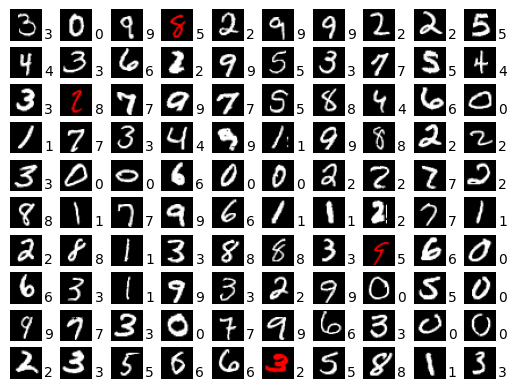

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.181760
Train Epoch: 2 [6400/60000 (11%)]	Loss: 0.084654
Train Epoch: 2 [12800/60000 (21%)]	Loss: 0.028075
Train Epoch: 2 [19200/60000 (32%)]	Loss: 0.069788
Train Epoch: 2 [25600/60000 (43%)]	Loss: 0.036800
Train Epoch: 2 [32000/60000 (53%)]	Loss: 0.195559
Train Epoch: 2 [38400/60000 (64%)]	Loss: 0.073981
Train Epoch: 2 [44800/60000 (75%)]	Loss: 0.015624
Train Epoch: 2 [51200/60000 (85%)]	Loss: 0.031445
Train Epoch: 2 [57600/60000 (96%)]	Loss: 0.183816

Test set: Average loss: 0.0879, Accuracy: 9758/10000 (97.58%)



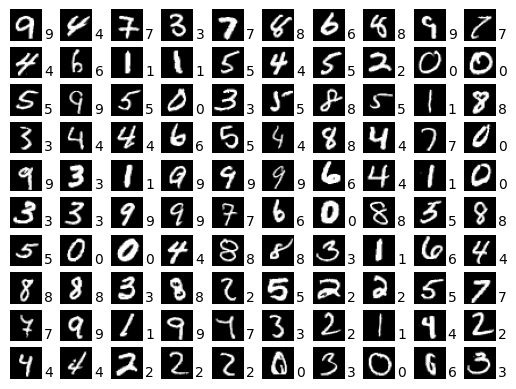

Train Epoch: 3 [0/60000 (0%)]	Loss: 0.021659
Train Epoch: 3 [6400/60000 (11%)]	Loss: 0.036321
Train Epoch: 3 [12800/60000 (21%)]	Loss: 0.005883
Train Epoch: 3 [19200/60000 (32%)]	Loss: 0.004056
Train Epoch: 3 [25600/60000 (43%)]	Loss: 0.134237
Train Epoch: 3 [32000/60000 (53%)]	Loss: 0.037222
Train Epoch: 3 [38400/60000 (64%)]	Loss: 0.045242
Train Epoch: 3 [44800/60000 (75%)]	Loss: 0.011040
Train Epoch: 3 [51200/60000 (85%)]	Loss: 0.107196
Train Epoch: 3 [57600/60000 (96%)]	Loss: 0.019065

Test set: Average loss: 0.0929, Accuracy: 9745/10000 (97.45%)



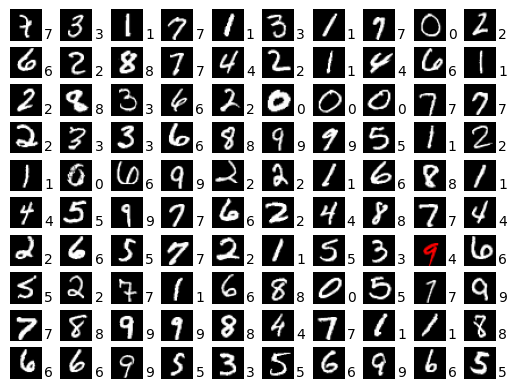

Train Epoch: 4 [0/60000 (0%)]	Loss: 0.011055
Train Epoch: 4 [6400/60000 (11%)]	Loss: 0.032215
Train Epoch: 4 [12800/60000 (21%)]	Loss: 0.236410
Train Epoch: 4 [19200/60000 (32%)]	Loss: 0.010732
Train Epoch: 4 [25600/60000 (43%)]	Loss: 0.033261
Train Epoch: 4 [32000/60000 (53%)]	Loss: 0.001899
Train Epoch: 4 [38400/60000 (64%)]	Loss: 0.018651
Train Epoch: 4 [44800/60000 (75%)]	Loss: 0.069642
Train Epoch: 4 [51200/60000 (85%)]	Loss: 0.023651
Train Epoch: 4 [57600/60000 (96%)]	Loss: 0.031341

Test set: Average loss: 0.0797, Accuracy: 9801/10000 (98.01%)



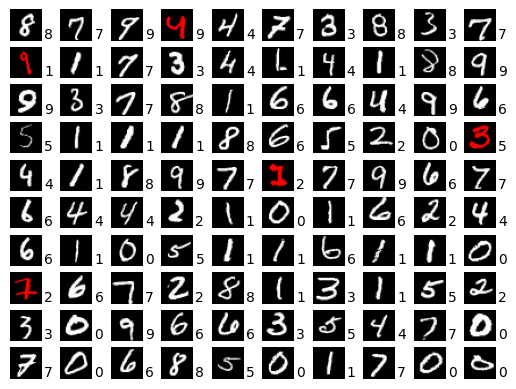

Train Epoch: 5 [0/60000 (0%)]	Loss: 0.002129
Train Epoch: 5 [6400/60000 (11%)]	Loss: 0.002122
Train Epoch: 5 [12800/60000 (21%)]	Loss: 0.000618
Train Epoch: 5 [19200/60000 (32%)]	Loss: 0.005385
Train Epoch: 5 [25600/60000 (43%)]	Loss: 0.003521
Train Epoch: 5 [32000/60000 (53%)]	Loss: 0.000689
Train Epoch: 5 [38400/60000 (64%)]	Loss: 0.004617
Train Epoch: 5 [44800/60000 (75%)]	Loss: 0.126679
Train Epoch: 5 [51200/60000 (85%)]	Loss: 0.005031
Train Epoch: 5 [57600/60000 (96%)]	Loss: 0.007821

Test set: Average loss: 0.0848, Accuracy: 9804/10000 (98.04%)



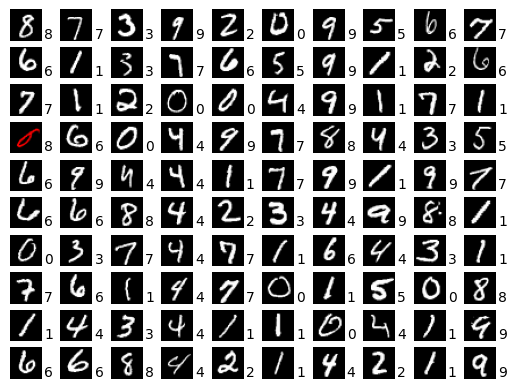

Train Epoch: 6 [0/60000 (0%)]	Loss: 0.000261
Train Epoch: 6 [6400/60000 (11%)]	Loss: 0.021899
Train Epoch: 6 [12800/60000 (21%)]	Loss: 0.000714
Train Epoch: 6 [19200/60000 (32%)]	Loss: 0.000357
Train Epoch: 6 [25600/60000 (43%)]	Loss: 0.001426
Train Epoch: 6 [32000/60000 (53%)]	Loss: 0.001166
Train Epoch: 6 [38400/60000 (64%)]	Loss: 0.001185
Train Epoch: 6 [44800/60000 (75%)]	Loss: 0.044417
Train Epoch: 6 [51200/60000 (85%)]	Loss: 0.000271
Train Epoch: 6 [57600/60000 (96%)]	Loss: 0.038145

Test set: Average loss: 0.0831, Accuracy: 9821/10000 (98.21%)



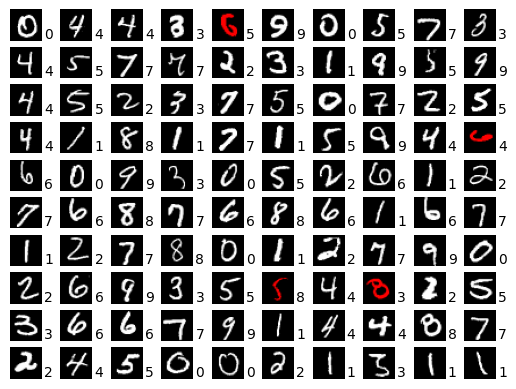

Train Epoch: 7 [0/60000 (0%)]	Loss: 0.001335
Train Epoch: 7 [6400/60000 (11%)]	Loss: 0.062264
Train Epoch: 7 [12800/60000 (21%)]	Loss: 0.000916
Train Epoch: 7 [19200/60000 (32%)]	Loss: 0.071779
Train Epoch: 7 [25600/60000 (43%)]	Loss: 0.023260
Train Epoch: 7 [32000/60000 (53%)]	Loss: 0.001242
Train Epoch: 7 [38400/60000 (64%)]	Loss: 0.000201
Train Epoch: 7 [44800/60000 (75%)]	Loss: 0.004694
Train Epoch: 7 [51200/60000 (85%)]	Loss: 0.046361
Train Epoch: 7 [57600/60000 (96%)]	Loss: 0.000105

Test set: Average loss: 0.0854, Accuracy: 9816/10000 (98.16%)



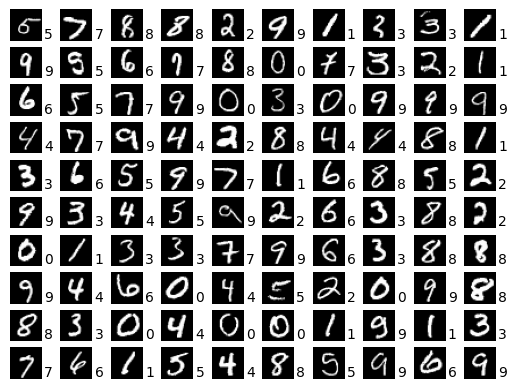

Train Epoch: 8 [0/60000 (0%)]	Loss: 0.002258
Train Epoch: 8 [6400/60000 (11%)]	Loss: 0.000761
Train Epoch: 8 [12800/60000 (21%)]	Loss: 0.016208
Train Epoch: 8 [19200/60000 (32%)]	Loss: 0.000442
Train Epoch: 8 [25600/60000 (43%)]	Loss: 0.000918
Train Epoch: 8 [32000/60000 (53%)]	Loss: 0.040277
Train Epoch: 8 [38400/60000 (64%)]	Loss: 0.000718
Train Epoch: 8 [44800/60000 (75%)]	Loss: 0.000264
Train Epoch: 8 [51200/60000 (85%)]	Loss: 0.001841
Train Epoch: 8 [57600/60000 (96%)]	Loss: 0.000038

Test set: Average loss: 0.0857, Accuracy: 9824/10000 (98.24%)



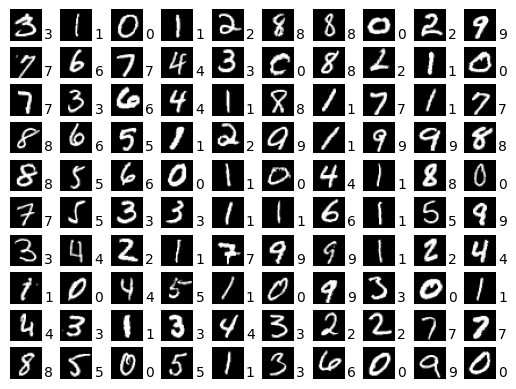

Train Epoch: 9 [0/60000 (0%)]	Loss: 0.000951
Train Epoch: 9 [6400/60000 (11%)]	Loss: 0.001682
Train Epoch: 9 [12800/60000 (21%)]	Loss: 0.000357
Train Epoch: 9 [19200/60000 (32%)]	Loss: 0.004101
Train Epoch: 9 [25600/60000 (43%)]	Loss: 0.000802
Train Epoch: 9 [32000/60000 (53%)]	Loss: 0.000689
Train Epoch: 9 [38400/60000 (64%)]	Loss: 0.000615
Train Epoch: 9 [44800/60000 (75%)]	Loss: 0.000284
Train Epoch: 9 [51200/60000 (85%)]	Loss: 0.001530
Train Epoch: 9 [57600/60000 (96%)]	Loss: 0.002403

Test set: Average loss: 0.0881, Accuracy: 9817/10000 (98.17%)



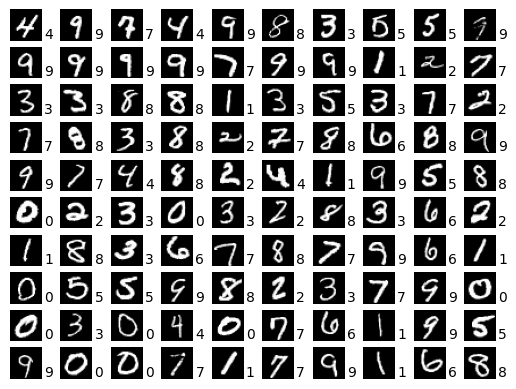

Train Epoch: 10 [0/60000 (0%)]	Loss: 0.000632
Train Epoch: 10 [6400/60000 (11%)]	Loss: 0.000472
Train Epoch: 10 [12800/60000 (21%)]	Loss: 0.000041
Train Epoch: 10 [19200/60000 (32%)]	Loss: 0.000815
Train Epoch: 10 [25600/60000 (43%)]	Loss: 0.000151
Train Epoch: 10 [32000/60000 (53%)]	Loss: 0.000063
Train Epoch: 10 [38400/60000 (64%)]	Loss: 0.000322
Train Epoch: 10 [44800/60000 (75%)]	Loss: 0.000830
Train Epoch: 10 [51200/60000 (85%)]	Loss: 0.000643
Train Epoch: 10 [57600/60000 (96%)]	Loss: 0.001008

Test set: Average loss: 0.0908, Accuracy: 9815/10000 (98.15%)



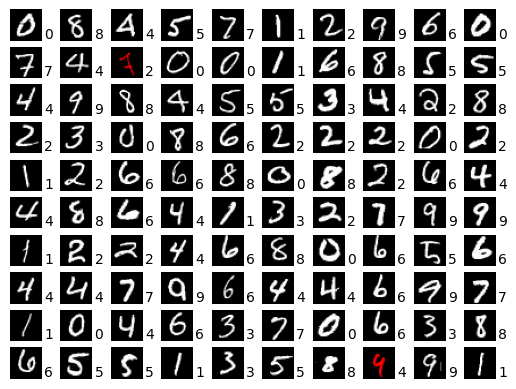

In [32]:
# hyper parameters
batch_size = 64
test_batch_size = 1000
epochs = 10
lr = 1.0
gamma = 0.7
log_interval = 100

# use GPU if available
use_cuda = torch.cuda.is_available()
kwargs = {'num_workers': 1, 'pin_memory': True} if use_cuda else {}

# initialize data loaders
train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=True, download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])), batch_size=batch_size, shuffle=True, **kwargs)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=False,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])),
    batch_size=test_batch_size, shuffle=True, **kwargs)

model = FCNet2()
if use_cuda:
    model = model.cuda()

# initialize optimizer and scheduler
optimizer = optim.Adadelta(model.parameters(), lr=lr)
scheduler = StepLR(optimizer, step_size=1, gamma=gamma)

for epoch in range(1, epochs + 1):
    # train one epoch
    train(model, use_cuda, train_loader, optimizer, epoch, log_interval)

    # run on test dataset
    validate(model, use_cuda, test_loader)
    scheduler.step()


    torch.save(model.state_dict(), "models/mnist/checkpoint.pt")